In [1]:
import sys
sys.path.append("../")

from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.data.datasets import register_coco_instances
# from detectron2.utils.logger import setup_logger
from detectron2.engine import DefaultTrainer
import logging
import cv2
import os
import random
import matplotlib.pyplot as plt

count = 0

c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


In [ ]:
path_dataset_train = './train'

In [ ]:
count +=1 # Registered datasets must have unique names

dataset_train_name = "my_dataset_train_" + str(count)

# dataset name, json path, images path
register_coco_instances(dataset_train_name, {}, path_dataset_train + "/instances_train.json" , path_dataset_train) 
                
nuts_metadata_train = MetadataCatalog.get(dataset_train_name)

dataset_dicts_train = DatasetCatalog.get(dataset_train_name)



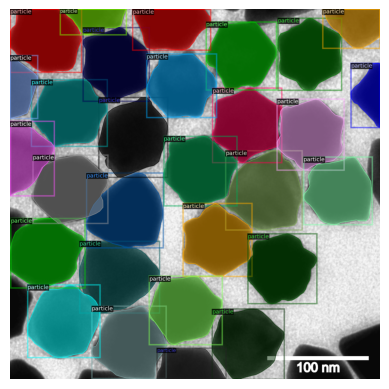

In [25]:
number_of_training_imgs_to_visualise = 1

for d in random.sample(dataset_dicts_train, number_of_training_imgs_to_visualise):

    img = cv2.imread(d["file_name"])

    visualizer = Visualizer(img[:, :, ::-1], metadata=nuts_metadata_train, scale=0.5)

    vis = visualizer.draw_dataset_dict(d)

    final_image = vis.get_image()[:, :, ::-1]

    plt.imshow(final_image, cmap='gray')
    plt.axis("off")


In [5]:
# # Optional: register a test dataset

# path_dataset_test = './val'

# dataset_test_name = "my_dataset_test_" + str(count)

# # dataset name, json path, images path
# register_coco_instances(dataset_test_name, {}, path_dataset_test + "/instances_val.json" , path_dataset_test) 
                
# nuts_metadata_test = MetadataCatalog.get(dataset_test_name)

# dataset_dicts_test = DatasetCatalog.get(dataset_test_name)

#### Define training config

In [6]:
model_device = 'cpu'
max_iter = 100 #Number of iterations the model is going to run
num_of_classes = 1
model_weights = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml")
#model_weights = "path/to/your/pretrained/model_final.pth"
imgs_per_batch = 2
learning_rate = 0.00025
batch_size_per_image = 1024


In [7]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = (dataset_train_name,)
cfg.DATASETS.TEST = ()
#cfg.DATASETS.TEST = (dataset_test_name,)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.DEVICE = model_device
cfg.MODEL.WEIGHTS = model_weights 
cfg.SOLVER.IMS_PER_BATCH = imgs_per_batch  # This is the real "batch size" commonly known to deep learning people
cfg.SOLVER.BASE_LR = learning_rate  # pick a good LR
cfg.SOLVER.MAX_ITER = max_iter    # 300 iterations seems good enough for this toy dataset; you will need to train longer for a practical dataset
cfg.SOLVER.STEPS = []        # do not decay learning rate
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = batch_size_per_image  # The "RoIHead batch size". 128 is faster, and good enough for this toy dataset (default: 512)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = num_of_classes 

# You can change the output dir path, by default a directory "output" is created in the current path
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

#### Start training

In [8]:
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[08/07 11:51:53 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (2, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (2,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (4, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (4,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (1, 256, 1, 1) in

[08/07 11:51:53 d2.engine.train_loop]: Starting training from iteration 0


c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\functional.py:512: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ..\aten\src\ATen\native\TensorShape.cpp:3588.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[08/07 11:58:17 d2.utils.events]:  eta: 0:25:19  iter: 19  total_loss: 1.826  loss_cls: 0.7474  loss_box_reg: 0.3923  loss_mask: 0.6765  loss_rpn_cls: 0.007004  loss_rpn_loc: 0.00699    time: 18.8624  last_time: 19.4178  data_time: 0.1863  last_data_time: 0.0019   lr: 4.7703e-05  max_mem: 0M
[08/07 12:04:23 d2.utils.events]:  eta: 0:18:46  iter: 39  total_loss: 1.135  loss_cls: 0.2741  loss_box_reg: 0.4398  loss_mask: 0.4031  loss_rpn_cls: 0.0009477  loss_rpn_loc: 0.005641    time: 18.5561  last_time: 19.7104  data_time: 0.0020  last_data_time: 0.0027   lr: 9.7653e-05  max_mem: 0M
[08/07 12:11:03 d2.utils.events]:  eta: 0:12:42  iter: 59  total_loss: 0.8584  loss_cls: 0.2029  loss_box_reg: 0.4726  loss_mask: 0.1851  loss_rpn_cls: 0.0001644  loss_rpn_loc: 0.004676    time: 19.0637  last_time: 18.9743  data_time: 0.0022  last_data_time: 0.0019   lr: 0.0001476  max_mem: 0M
[08/07 12:18:09 d2.utils.events]:  eta: 0:06:34  iter: 79  total_loss: 0.7242  loss_cls: 0.1395  loss_box_reg: 0.447 